 # Step 11 — MY versus NRT



 Step 07 found that on live NRT data the model does **worse than the blend rule**, although on MY data

 (2025 test year, step 09) it does better. This step asks why.



 **Part A (this part): season or data?** The live evaluation covers only a few weeks of late autumn.

 We score the model, the blend rule and "no change" on MY data in **the same calendar window** of every

 year 2017–2025, using the same rules as step 07. If the model also loses in that window on MY, the live

 result is seasonal; if it wins, something about the NRT inputs is the cause. Two further checks look for

 that cause: whether any input is shifted on NRT, and whether hiding temperature from the model changes

 the live result.



 The model was trained on issue days up to 2024-12-24, so only the **2025** window is unseen; earlier

 windows are in its training data and flatter it.



 **Part B (from about 19 November 2026):** compare NRT with the delayed MY interim data (MYINT) on the

 same days.

In [1]:
import json
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

from chlforecast import archive, config, forecast, scoring
from chlforecast import features as F

bundle = joblib.load(config.MODEL_PATH)
mask = bundle["model_mask"].values == 1
latitude = bundle["model_mask"].latitude.values
longitude = bundle["model_mask"].longitude.values
horizons = [int(h) for h in bundle["forecast_horizons_days"]]
trained_until = pd.Timestamp(bundle["training_issue_date_range"][1])
min_chl = bundle["preprocessing"]["min_plausible_chl_mg_m3"]
METHODS = ["Forecast model", "Blend rule", "No change"]

# Live data: the NRT archive, on one daily calendar, exactly as in step 07.
chl_dates, chl_values, _ = archive.load("chl", latitude, longitude)
sst_dates, sst_values, _ = archive.load("sst", latitude, longitude)
chl_values = F.quality_control(chl_values, minimum=min_chl)
live_dates = pd.date_range(chl_dates[0], max(chl_dates[-1] + pd.Timedelta(days=config.CHL_LAG_DAYS), sst_dates[-1]))


def on_calendar(source_dates, values):
    out = np.full((len(live_dates),) + values.shape[1:], np.nan, dtype="float32")
    keep = source_dates.isin(live_dates)
    out[live_dates.get_indexer(source_dates[keep])] = values[keep]
    return out


live = {"chl": on_calendar(chl_dates, chl_values), "sst": on_calendar(sst_dates, sst_values), "dates": live_dates}

# The live evaluation window: from the first issue day with a complete history
# to the last archived chlorophyll day (the last possible target).
first_issue = chl_dates[0] + pd.Timedelta(days=config.CHL_HISTORY_DAYS + config.CHL_LAG_DAYS - 1)
last_target = chl_dates[-1]
WINDOW = (f"{first_issue:%m-%d}", f"{last_target:%m-%d}")
YEARS = list(range(2017, 2026))
in_training = [y for y in YEARS if pd.Timestamp(f"{y}-{WINDOW[1]}") <= trained_until]
unseen = [y for y in YEARS if y not in in_training]

# MY data: the collated observations of step 02.
observations = xr.open_dataset(config.PROCESSED / "malta_daily_observations.nc")
GRID = ("time", "latitude", "longitude")


def my_block(year):
    """MY chlorophyll and temperature for the window of one year, starting 25 days
    early so every 7-day history (and the 7-day temperature change) is complete."""
    first = pd.Timestamp(f"{year}-{WINDOW[0]}")
    block = observations.sel(time=slice(first - pd.Timedelta(days=25), pd.Timestamp(f"{year}-{WINDOW[1]}")))
    return {"chl": F.quality_control(block["chl"].transpose(*GRID).values, minimum=min_chl),
            "sst": block["sst_c"].transpose(*GRID).values,
            "dates": pd.DatetimeIndex(block.time.values)}


print(f"Model: {config.MODEL_PATH.name}, trained on issue days up to {trained_until:%Y-%m-%d}")
print(f"Window: issue days from {WINDOW[0]}, targets up to {WINDOW[1]}; "
      f"MY years in training {in_training[0]}–{in_training[-1]}, unseen {unseen}")


Model: chl_forecast_step09.joblib, trained on issue days up to 2024-12-24
Window: issue days from 10-26, targets up to 11-13; MY years in training 2017–2024, unseen [2025]


In [2]:
def build_inputs(block, hide_sst=False):
    """The model's inputs, built by the shared recipe (step 04). With hide_sst,
    the model sees no temperature at all, as on a fully cloudy day."""
    sst = np.full_like(block["sst"], np.nan) if hide_sst else block["sst"]
    inputs = F.model_inputs(block["chl"], sst, block["dates"], mask, bundle["monthly_log_climatology"].values,
                            bundle["monthly_sst_climatology"].values, bundle["coast_distance_km"].values,
                            latitude, longitude)
    return {name: np.broadcast_to(values, block["chl"].shape) for name, values in inputs.items()}


def window_forecasts(block, year, hide_sst=False):
    """Forecasts and targets in the window, scored with the rules of step 07:
    only pixels with a usable latest observation and an observed target count."""
    dates = block["dates"]
    first, last = pd.Timestamp(f"{year}-{WINDOW[0]}"), pd.Timestamp(f"{year}-{WINDOW[1]}")
    inputs = build_inputs(block, hide_sst)
    out = {}
    for h in horizons:
        issue_index = np.flatnonzero((dates >= first) & (dates + pd.Timedelta(days=h) <= last))
        model = forecast.model_forecast(bundle, inputs, dates, h)[issue_index]
        blend = forecast.blend_forecast(bundle, inputs, dates, h)[issue_index]
        persistence = inputs["chl_latest"][issue_index]
        target = block["chl"][issue_index + h]
        scored = (np.isfinite(target) & (target > 0) & mask[None]
                  & np.isfinite(persistence) & np.isfinite(model))
        day = np.broadcast_to(dates[issue_index].values[:, None, None], scored.shape)[scored]
        out[h] = {"observed": target[scored], "day": day,
                  "Forecast model": model[scored], "Blend rule": blend[scored], "No change": persistence[scored]}
    return out


def summarise(parts, label):
    """Scores and gain over the blend, pooling forecasts from one or more windows."""
    rows = []
    for h in horizons:
        pooled = {key: np.concatenate([p[h][key] for p in parts]) for key in ["observed", "day"] + METHODS}
        n_days = np.unique(pooled["day"]).size
        gain, low, high = (scoring.log_rmse_gain_interval(
            pooled["observed"], pooled["Forecast model"], pooled["Blend rule"], pooled["day"])
            if n_days >= 10 else (np.nan, np.nan, np.nan))
        row = {"Data": label, "Horizon": f"+{h}d", "Issue days": n_days,
               "Pixel-days per issue day": pooled["observed"].size / n_days}
        for method in METHODS:
            row[f"RMSE log10: {method}"] = scoring.chl_scores(pooled["observed"], pooled[method])["RMSE (log10)"]
        row.update({"Gain over blend (%)": gain, "95% low": low, "95% high": high})
        rows.append(row)
    return rows


live_forecasts = window_forecasts(live, last_target.year)
my_forecasts = {}
for year in YEARS:
    my_forecasts[year] = window_forecasts(my_block(year), year)
    print(f"{year}: scored issue days " + ", ".join(
        f"+{h}d {np.unique(my_forecasts[year][h]['day']).size}" for h in horizons), flush=True)

TABLE_FORMAT = {"Issue days": "{:,.0f}", "Pixel-days per issue day": "{:,.0f}",
                **{f"RMSE log10: {m}": "{:.4f}" for m in METHODS},
                "Gain over blend (%)": "{:+.1f}", "95% low": "{:+.1f}", "95% high": "{:+.1f}"}


2017: scored issue days +1d 15, +4d 12, +7d 9
2018: scored issue days +1d 13, +4d 12, +7d 11
2019: scored issue days +1d 16, +4d 13, +7d 10
2020: scored issue days +1d 18, +4d 15, +7d 12
2021: scored issue days +1d 12, +4d 12, +7d 10
2022: scored issue days +1d 18, +4d 15, +7d 12
2023: scored issue days +1d 15, +4d 12, +7d 9
2024: scored issue days +1d 15, +4d 12, +7d 10
2025: scored issue days +1d 18, +4d 15, +7d 12


 ### Live NRT against the same window on MY



 The live row repeats step 07's result (same rules, same numbers). A positive gain means the model beats the

 blend rule.

In [3]:
comparison = pd.DataFrame(
    summarise([live_forecasts], f"Live NRT {last_target.year}")
    + summarise([my_forecasts[y] for y in unseen], f"MY {', '.join(map(str, unseen))} (unseen)")
    + summarise([my_forecasts[y] for y in in_training], f"MY {in_training[0]}–{in_training[-1]} (in training)")
).set_index(["Horizon", "Data"]).sort_index(level="Horizon", sort_remaining=False)
display(comparison.style.format(TABLE_FORMAT, na_rep="—"))


 ### Year by year



 Is the live result within the usual year-to-year range? The "no change" error measures how much

 chlorophyll changed from day to day, independent of any model: a hard year raises it for every method.

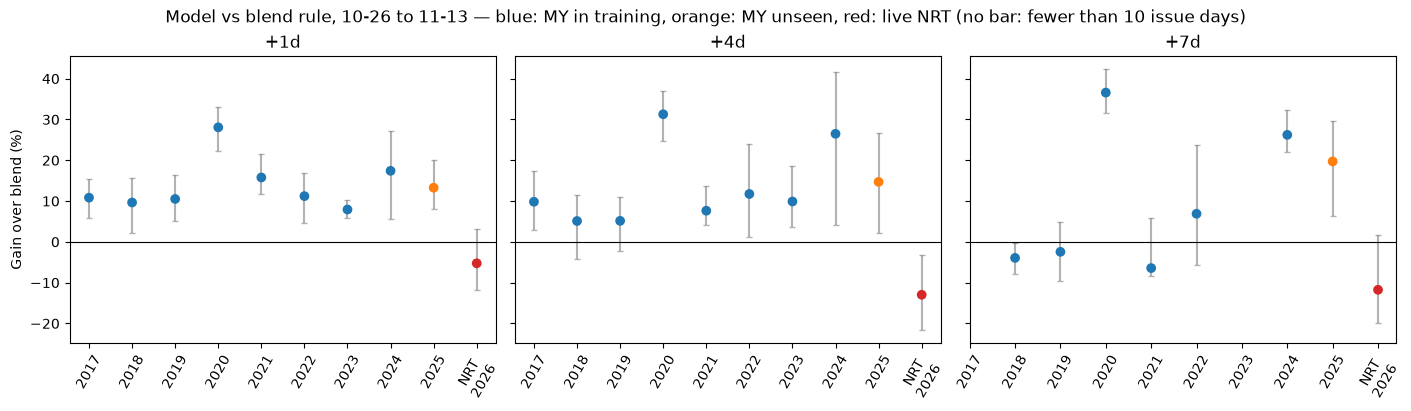

In [4]:
yearly = pd.DataFrame([dict(r, Year=str(y)) for y in YEARS for r in summarise([my_forecasts[y]], str(y))]
                      + [dict(r, Year=f"Live NRT {last_target.year}") for r in summarise([live_forecasts], "live")])
columns = ["Gain over blend (%)", "RMSE log10: Blend rule", "RMSE log10: No change"]
yearly_table = yearly.pivot(index="Year", columns="Horizon", values=columns).loc[yearly["Year"].unique()]
display(yearly_table.style.format("{:.3f}", na_rep="—")
        .format("{:+.1f}", subset=["Gain over blend (%)"], na_rep="—"))

fig, axes = plt.subplots(1, len(horizons), figsize=(14, 4), sharey=True, constrained_layout=True)
for ax, h in zip(axes, horizons):
    y = yearly[yearly["Horizon"] == f"+{h}d"].reset_index(drop=True)
    colours = ["tab:red" if year.startswith("Live") else "tab:orange" if int(year) in unseen else "tab:blue"
               for year in y["Year"]]
    ax.errorbar(y.index, y["Gain over blend (%)"],
                yerr=[y["Gain over blend (%)"] - y["95% low"], y["95% high"] - y["Gain over blend (%)"]],
                fmt="none", ecolor="grey", alpha=0.6, capsize=2)
    ax.scatter(y.index, y["Gain over blend (%)"], c=colours, zorder=3)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(y.index, [s.replace("Live NRT ", "NRT\n") for s in y["Year"]], rotation=60)
    ax.set_title(f"+{h}d")
axes[0].set_ylabel("Gain over blend (%)")
fig.suptitle(f"Model vs blend rule, {WINDOW[0]} to {WINDOW[1]} — blue: MY in training, "
             "orange: MY unseen, red: live NRT (no bar: fewer than 10 issue days)")
plt.show()


 ### Are any inputs shifted on NRT?



 The blend rule uses only the latest chlorophyll; the model also uses temperature and other inputs derived

 from chlorophyll. An input that is shifted on NRT would hurt the model but not the blend. Shift is the live

 mean minus the MY mean, in MY standard deviations, over pixels with a usable latest observation.

In [5]:
def window_inputs(block, year):
    dates = block["dates"]
    keep = np.flatnonzero((dates >= pd.Timestamp(f"{year}-{WINDOW[0]}")) & (dates <= pd.Timestamp(f"{year}-{WINDOW[1]}")))
    inputs = build_inputs(block)
    usable = np.isfinite(inputs["chl_latest"][keep]) & mask[None]
    return {name: np.asarray(inputs[name])[keep][usable] for name in bundle["feature_names"]}


live_x = window_inputs(live, last_target.year)
my_x = {year: window_inputs(my_block(year), year) for year in YEARS}
rows = []
for name in bundle["feature_names"]:
    yearly_means = np.array([np.nanmean(my_x[y][name]) for y in YEARS])
    pooled = np.concatenate([my_x[y][name] for y in YEARS])
    live_mean = np.nanmean(live_x[name])
    rows.append({
        "Input": name,
        "Live NRT mean": live_mean,
        "MY mean": np.nanmean(pooled),
        "MY yearly means": f"{yearly_means.min():.3g} to {yearly_means.max():.3g}",
        "Shift (MY s.d.)": (live_mean - np.nanmean(pooled)) / np.nanstd(pooled),
        "Live missing (%)": 100 * np.mean(~np.isfinite(live_x[name])),
        "MY missing (%)": 100 * np.mean(~np.isfinite(pooled)),
    })
shifts = pd.DataFrame(rows).set_index("Input").sort_values("Shift (MY s.d.)", key=np.abs, ascending=False)
display(shifts.style.format({"Live NRT mean": "{:.4g}", "MY mean": "{:.4g}", "Shift (MY s.d.)": "{:+.2f}",
                             "Live missing (%)": "{:.1f}", "MY missing (%)": "{:.1f}"}))


,Live NRT mean,MY mean,MY yearly means,Shift (MY s.d.),Live missing (%),MY missing (%)
Input,,,,,,
sst_anomaly,-0.7461,0.2339,-1.67 to 1.48,-0.75,50.1,43.5
chl_observations_7d,2.849,3.765,1.73 to 5.68,-0.54,0.0,0.0
sst_c,22.16,22.7,21.4 to 23.9,-0.46,48.6,43.5
sst_change_7d,-0.5457,-0.3338,-0.542 to -0.184,-0.45,48.6,44.6
chl_age_days,2.662,2.156,1.44 to 4.15,+0.27,0.0,0.0
chl_trend_log,0.01254,-0.0001823,-0.0112 to 0.0118,+0.18,1.4,2.3
chl_anomaly_log,0.001689,-0.01994,-0.0781 to 0.0617,+0.16,0.0,0.0
sst_observed,0.5136,0.5648,0.241 to 0.89,-0.10,0.0,0.0
chl_latest,0.06473,0.06022,0.048 to 0.0829,+0.07,0.0,0.0


 ### Does NRT temperature cause it?



 NRT temperature is a different product from MY (0.0625° rather than 0.05°). Here the model is re-scored with

 temperature hidden, as on a fully cloudy day. If the live loss disappears, temperature is the cause; if it

 remains, the cause lies in the chlorophyll inputs.

In [6]:
ablation = pd.DataFrame(
    summarise([live_forecasts], "Live NRT: with temperature")
    + summarise([window_forecasts(live, last_target.year, hide_sst=True)], "Live NRT: temperature hidden")
    + summarise([my_forecasts[y] for y in unseen], f"MY {unseen[0]}: with temperature")
    + summarise([window_forecasts(my_block(y), y, hide_sst=True) for y in unseen], f"MY {unseen[0]}: temperature hidden")
).set_index(["Horizon", "Data"]).sort_index(level="Horizon", sort_remaining=False)
display(ablation[["Issue days", "RMSE log10: Forecast model", "RMSE log10: Blend rule",
                  "Gain over blend (%)", "95% low", "95% high"]].style.format(TABLE_FORMAT, na_rep="—"))


In [7]:
run = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
out_dir = config.PROCESSED / "my_vs_nrt" / run
out_dir.mkdir(parents=True, exist_ok=True)
for name, table in [("window_comparison", comparison), ("window_by_year", yearly.set_index(["Year", "Horizon"])),
                    ("input_shifts", shifts), ("temperature_ablation", ablation)]:
    table.reset_index().to_json(out_dir / f"{name}.json", orient="records", indent=2, double_precision=10)
fig.savefig(out_dir / "window_gain_by_year.png", dpi=150)
(out_dir / "provenance.json").write_text(json.dumps({
    "saved_utc": datetime.now(timezone.utc).isoformat(),
    "model_file": config.MODEL_PATH.name,
    "model_training_issue_dates": bundle["training_issue_date_range"],
    "window_first_issue_to_last_target": list(WINDOW),
    "live_chl_archive_days": [f"{chl_dates[0]:%Y-%m-%d}", f"{chl_dates[-1]:%Y-%m-%d}"],
    "my_years_in_training": in_training,
    "my_years_unseen": unseen,
    "my_source": "malta_daily_observations.nc",
    "scoring_rules": "As step 07: observed target, usable latest observation, modelled pixel",
}, indent=2), encoding="utf-8")
print(f"Saved to {out_dir}")


Saved to /Users/alangatt/git/mcast/research/mcast.pages.chl_prediction/experiment_v2/data/processed/my_vs_nrt/20261114T124434Z
